---
title: "Work and Energy — Level 2"
short_title: "04 Work & Energy"
numbering:
  heading_2: true
  equation: true
---

# Work and Energy

:::{seealso} Math for this topic
- [M3: Multivariable calculus](../math/03-multivariable-calculus.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 6–7 | Energy bookkeeping with spring and gravitational potential energy |
| **2** | **Taylor, ch. 4** | **Gradient of a potential, curl test, 1D energy analysis and effective potentials** |
| 3 | Goldstein, ch. 1–2 | Energy function h, Jacobi integral, generalized potentials |

The new skill at this level: deciding when a potential energy exists, and reading the motion off a potential-energy graph without solving the ODE

Math for this topic: M3, multivariable calculus (and the Chapter 16 vector calculus notes for line integrals and curl).
:::

Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## The Work–Energy Theorem

The work done by a force along a path $C$ is the line integral

$$
W = \int_C\vec{F}\cdot d\vec{r} .
$$

If $\vec{F}$ is the **net** force, Newton's second law turns the integrand into an exact derivative: $\vec{F}\cdot d\vec{r} = m\dot{\vec{v}}\cdot\vec{v}\,dt = d\big(\tfrac12mv^2\big)$. So

$$
\Delta T = W_{\text{net}} .
$$ (eq-work-energy)

This holds for every force. Potential energy is useful only for a special class of forces.

## Conservative Forces

:::{prf:definition} Conservative force
:label: def-conservative-force

A force $\vec{F}(\vec{r})$ is **conservative** if (1) it depends only on position, and (2) the work it does between any two points is independent of the path.
:::

For such a force, fix a reference point $\vec{r}_0$ and define the **potential energy**

$$
U(\vec{r}) = -\int_{\vec{r}_0}^{\vec{r}}\vec{F}\cdot d\vec{r}' ,
\qquad\text{so that}\qquad
\vec{F} = -\nabla U .
$$ (eq-potential)

Then the work done by $\vec{F}$ is $-\Delta U$, and {eq}`eq-work-energy` becomes conservation of $E = T + U$. If other, nonconservative forces act (friction, drag), they change $E$ by exactly the work they do:

$$
\Delta E = W_{\text{nc}} .
$$

### Testing for a conservative force

Checking path independence directly is impractical. Instead, use the curl test (proved with Stokes' theorem in the Chapter 16 notes):

$$
\nabla\times\vec{F} = \vec{0} \text{ on a simply connected region} \quad\Longleftrightarrow\quad \text{path independent} .
$$

Two families of forces are automatically conservative:

- **Uniform forces** (gravity near the surface): $U = mgz$.
- **Central, spherically symmetric forces** $\vec{F} = f(r)\hat{r}$: $U = -\int f(r)\,dr$. Gravity, electrostatics and springs are all in this family.

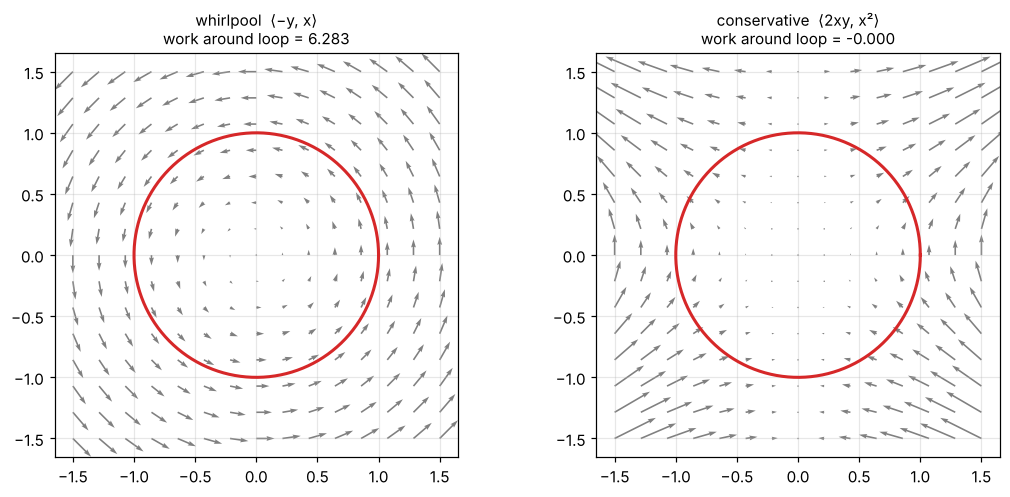

In [2]:
#| label: fig-nonconservative
#| caption: The force F = k⟨−y, x⟩ (a whirlpool) has curl 2k ≠ 0. Going around the unit circle counterclockwise it does work 2πk, so no potential energy can exist; the conservative force ⟨2xy, x²⟩ does zero work around the same loop.
xs = np.linspace(-1.5, 1.5, 15)
X, Y = np.meshgrid(xs, xs)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
t = np.linspace(0, 2 * np.pi, 400)
loops = {"whirlpool  ⟨−y, x⟩": (lambda x, y: (-y, x)), "conservative  ⟨2xy, x²⟩": (lambda x, y: (2 * x * y, x**2))}
for ax, (name, F) in zip(axes, loops.items()):
    U, V = F(X, Y)
    ax.quiver(X, Y, U, V, color="gray")
    ax.plot(np.cos(t), np.sin(t), "tab:red", lw=2)
    Fx, Fy = F(np.cos(t), np.sin(t))
    W = np.trapezoid(Fx * (-np.sin(t)) + Fy * np.cos(t), t)
    ax.set_title(f"{name}\nwork around loop = {W:.3f}", fontsize=10)
    ax.set_aspect("equal")
plt.tight_layout(); plt.show()

In [3]:
# Curl test and potential for a 3D force
x, y, z = sp.symbols("x y z", real=True)
F = sp.Matrix([y**2, 2 * x * y + z, y])
curl = sp.Matrix([sp.diff(F[2], y) - sp.diff(F[1], z),
                  sp.diff(F[0], z) - sp.diff(F[2], x),
                  sp.diff(F[1], x) - sp.diff(F[0], y)])
print("curl F =", curl.T)

U = -sp.integrate(F[0], x)                                   # U = -x y^2 + g(y, z)
U += -sp.integrate(sp.simplify(F[1] + sp.diff(U, y)), y)     # fix the y dependence
U += -sp.integrate(sp.simplify(F[2] + sp.diff(U, z)), z)     # fix the z dependence
print("U =", sp.simplify(U))
print("check -grad U == F:", sp.simplify(-sp.Matrix([sp.diff(U, v) for v in (x, y, z)]) - F).T)

curl F = Matrix([[0, 0, 0]])
U = y*(-x*y - z)
check -grad U == F: Matrix([[0, 0, 0]])


:::{note} Time-dependent potentials
If $U$ depends explicitly on time, $\vec{F} = -\nabla U(\vec{r}, t)$ still holds, but energy is no longer conserved: $dE/dt = \partial U/\partial t$. A child pumping a swing changes the effective potential in time, and that is how the swing gains energy. In Lagrangian language, explicit time dependence is what breaks energy conservation (a Level 3 idea via Noether's theorem).
:::

### Exercises

1. Show that $\vec{F} = \langle y^2,\ 2xy + z,\ y\rangle$ is conservative and find $U$ (the code above checks your answer).
2. Is $\vec{F} = \langle y, -x, 0\rangle$ conservative? Find the work it does around the unit circle, counterclockwise.
3. A block slides 2.0 m across a floor with $\mu_k = 0.3$, starting at 3.0 m/s. Use $\Delta E = W_{\text{nc}}$ to find its final speed.

:::{dropdown} Hints
1. Compute all three curl components, then integrate component by component.
2. Compute $\partial Q/\partial x - \partial P/\partial y$. For the work, use $\vec{r}(t) = \langle\cos t, \sin t\rangle$.
3. $W_{\text{nc}} = -\mu_kmgd$; the mass cancels.
:::

:::{dropdown} Answers
1. $\nabla\times\vec{F} = \vec{0}$, and $U = -(xy^2 + yz)$ plus a constant.
2. No: the curl's $z$-component is $-2$. The work is $-2\pi$.
3. $v^2 = 9 - 2(0.3)(9.81)(2) \approx 2.2$, so $v\approx1.5$ m/s.
:::

## Energy in One Dimension

For a particle moving along a line under a force $F(x) = -U'(x)$, energy conservation is a first-order ODE:

$$
\tfrac12m\dot x^2 + U(x) = E \qquad\Longrightarrow\qquad \dot x = \pm\sqrt{\frac{2}{m}\big(E - U(x)\big)} .
$$

It is separable, which gives the motion as a quadrature:

$$
t = \int_{x_0}^{x}\frac{dx'}{\sqrt{\tfrac2m\big(E - U(x')\big)}} .
$$ (eq-quadrature)

Even when this integral cannot be done in closed form, the **graph of $U(x)$** shows the motion:

- The particle can only be where $U(x)\le E$. The points where $U = E$ are **turning points**.
- Between two turning points the motion is a periodic oscillation with period $\tau = 2\int_{x_1}^{x_2}dx/|\dot x|$.
- **Equilibria** are where $U'(x_0) = 0$. A minimum is stable. Expanding $U\approx U(x_0) + \tfrac12U''(x_0)(x - x_0)^2$ gives small oscillations with

$$
\omega = \sqrt{\frac{U''(x_0)}{m}} .
$$ (eq-small-osc)

Every smooth potential well looks like a spring near its bottom. That is why simple harmonic motion is everywhere.

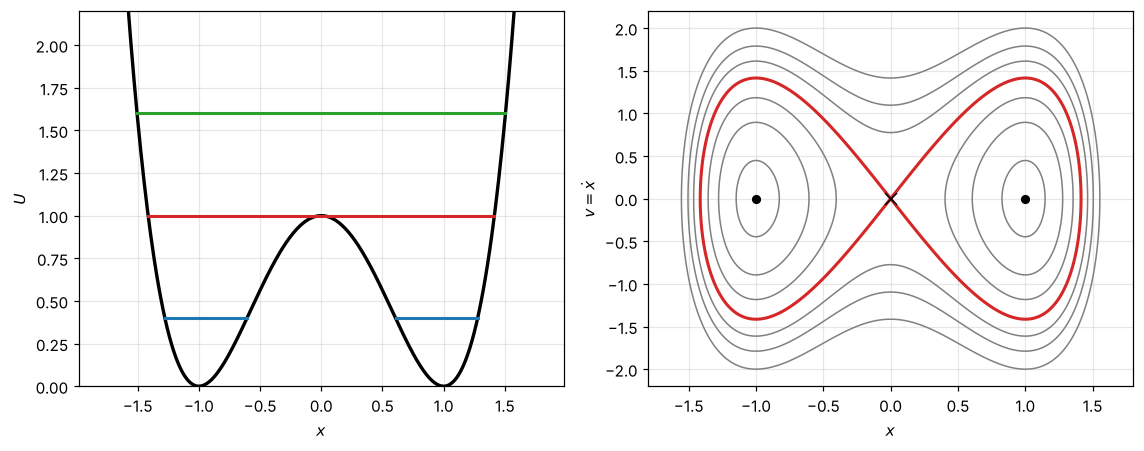

In [4]:
#| label: fig-double-well
#| caption: The double-well potential U = U₀[(x/a)² − 1]² (left) and its phase portrait, curves of constant energy in the (x, v) plane (right). Below E = U₀ the particle is trapped in one well; above it, it travels over both. The separatrix (red) divides the two kinds of motion.
U0, a, m = 1.0, 1.0, 1.0
x = np.linspace(-1.8, 1.8, 400)
U = U0 * ((x / a)**2 - 1)**2
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
axes[0].plot(x, U, "k", lw=2.2)
for E, c in [(0.4, "tab:blue"), (1.0, "tab:red"), (1.6, "tab:green")]:
    inside = U <= E
    axes[0].plot(np.where(inside, x, np.nan), np.full_like(x, E), color=c, lw=2)
axes[0].set_ylim(0, 2.2); axes[0].set_xlabel("$x$"); axes[0].set_ylabel("$U$")

X, V = np.meshgrid(x, np.linspace(-2.2, 2.2, 400))
Etot = 0.5 * m * V**2 + U0 * ((X / a)**2 - 1)**2
axes[1].contour(X, V, Etot, levels=[0.1, 0.4, 0.7, 1.3, 1.6, 2.0], colors="gray", linewidths=1)
axes[1].contour(X, V, Etot, levels=[1.0], colors="tab:red", linewidths=2)
axes[1].plot([-a, a], [0, 0], "ko", ms=5); axes[1].plot(0, 0, "kx", ms=8)
axes[1].set_xlabel("$x$"); axes[1].set_ylabel(r"$v = \dot x$")
plt.tight_layout(); plt.show()

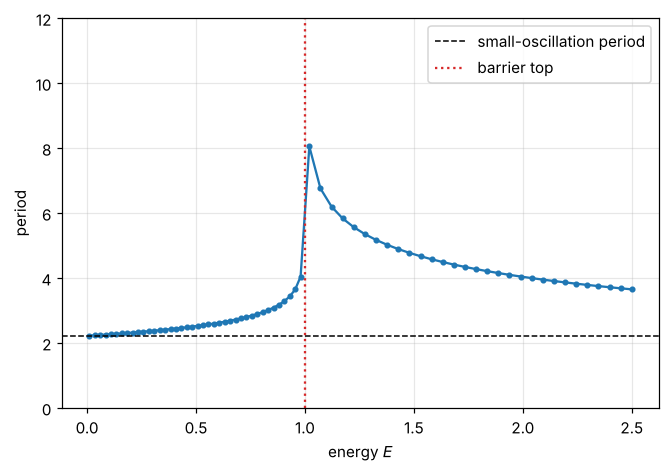

In [5]:
#| label: fig-period-energy
#| caption: Period of oscillation in the double well, from the quadrature integral. At low energy it matches the small-oscillation value 2π/√(8U₀/ma²); it grows without bound as E approaches the barrier top, where the particle lingers near the unstable equilibrium.
U0, a, m = 1.0, 1.0, 1.0
def period(E):
    if E < U0:   # trapped in the right well: turning points from U = E
        x1, x2 = a * np.sqrt(1 - np.sqrt(E / U0)), a * np.sqrt(1 + np.sqrt(E / U0))
        f = lambda x: 1 / np.sqrt(2 / m * (E - U0 * ((x / a)**2 - 1)**2))
        return 2 * quad(f, x1, x2, limit=200)[0]
    x2 = a * np.sqrt(1 + np.sqrt(E / U0))
    f = lambda x: 1 / np.sqrt(2 / m * (E - U0 * ((x / a)**2 - 1)**2))
    return 2 * quad(f, -x2, x2, limit=200, points=[0])[0]

Es = np.r_[np.linspace(0.01, 0.98, 40), np.linspace(1.02, 2.5, 30)]
fig, ax = plt.subplots()
ax.plot(Es, [period(E) for E in Es], "o-", ms=3)
ax.axhline(2 * np.pi / np.sqrt(8 * U0 / (m * a**2)), color="k", ls="--", lw=1, label="small-oscillation period")
ax.axvline(U0, color="tab:red", ls=":", label="barrier top")
ax.set_xlabel("energy $E$"); ax.set_ylabel("period"); ax.set_ylim(0, 12); ax.legend()
plt.show()

:::{tip} Why the period jumps at $E = U_0$
Just above the barrier, one full cycle crosses **both** wells, so the period roughly doubles compared with a trip within a single well. Right at $E = U_0$, the particle would take infinite time to reach the top. Phase portraits and separatrices return in the Hamiltonian notes and in the math notes on nonlinear systems.
:::

## One Coordinate, Curved Paths

Energy methods work for any system described by a single coordinate, even when the motion is curved. For a bead sliding on a frictionless wire $y = f(x)$ in a vertical plane, $v^2 = \dot x^2(1 + f'^2)$, so

$$
E = \tfrac12m\left(1 + f'(x)^2\right)\dot x^2 + mgf(x) .
$$

The normal force does no work and never appears. The factor $1 + f'^2$ acts like a position-dependent mass. Systems with constraints and one degree of freedom (Atwood machines, beads, rolling objects) all reduce this way, and that is the bridge to Lagrangian mechanics.

### Exercises

1. Find the frequency of small oscillations about $x = a$ in the double well $U = U_0[(x/a)^2 - 1]^2$.
2. A bead slides on a frictionless wire $y = x^2/(2R)$ in a vertical plane. Find the frequency of small oscillations about the bottom.
3. A particle in the well $U = -U_0\,\mathrm{sech}^2(x/a)$ starts at $x = 0$ with speed $v_0$. What is the largest $v_0$ for which it stays trapped?

:::{dropdown} Hints
1. Use {eq}`eq-small-osc`.
2. Near the bottom, $f'^2\approx0$; keep only quadratic terms in $E$.
3. Trapped means $E < U(\pm\infty)$.
:::

:::{dropdown} Answers
1. $U''(a) = 8U_0/a^2$, so $\omega = \sqrt{8U_0/(ma^2)}$.
2. $E\approx\tfrac12m\dot x^2 + \tfrac12(mg/R)x^2$, so $\omega = \sqrt{g/R}$, like a pendulum of length $R$.
3. $\tfrac12mv_0^2 - U_0 < 0$, so $v_0 < \sqrt{2U_0/m}$.
:::

## Summary

- $\Delta T = W_{\text{net}}$ always. Potential energy exists only for conservative forces, those with $\nabla\times\vec{F} = \vec{0}$ on a simply connected region.
- $\vec{F} = -\nabla U$, and $\Delta E = W_{\text{nc}}$ for the other forces.
- In 1D, $E = \tfrac12m\dot x^2 + U(x)$ is a separable ODE. The graph of $U$ gives turning points, equilibria and their stability, and $\omega = \sqrt{U''/m}$ for small oscillations.
- Phase portraits are the energy contours in the $(x, \dot x)$ plane. Separatrices divide qualitatively different motions.
- Any one-coordinate system, curved path or not, can be treated with energy alone.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.